# R2 · Whole-tile accuracy (Fig 2C, Supplementary Fig S5)

Spindle against Spindle-naive (the exact d_B) on every held-out tile of the 8 sections × seeds 0–4, at every g of the
trade-off, and the typical query of the band plot. Definitions and declared expectations are in
`experiments/common/whole_tile.py` and `retrieval.py`.

* **Prerequisites:** `R0_index_cache` (builds). Fig 2 also needs `R1_index_cost` and `R4_timing`.
* **Writes** `results/whole_tile/`:
  * `per_dataset/<key>/seed<k>.csv`: one row per (held-out query, g)
  * `nx_seeds.csv`, `nx.csv`: per (dataset, seed, g) and per (dataset, g) over seeds
  * `band/<key>.npz`, `band/typical.csv`: the typical query's d_B to every index tile and the rows Spindle returned
* **Skips** per-(dataset, seed) files that already exist (`FORCE = True` redoes them).
* **Runtime / memory:** under 1 h on one core.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import results_io as rio
import retrieval as rt
import whole_tile as wt

FORCE = False
TOPIC = "whole_tile"
OUT = rio.topic(TOPIC)
print(data.stamp())

{'tag': 'method-v2', 'describe': 'method-v3-dirty', 'commit': 'b35f7d4'}


## Spindle against Spindle-naive, every held-out tile and g

In [2]:
(OUT / "band").mkdir(exist_ok=True)
for key in data.indexed_keys():
    for seed in data.SEEDS:
        f = OUT / "per_dataset" / key / f"seed{seed}.csv"
        band = OUT / "band" / f"{key}.npz"
        if f.exists() and (seed != data.EXAMPLE_SEED or band.exists()) and not FORCE:
            continue
        df, found, D, test = wt.nx_rows(key, seed)
        rio.write_csv(df, TOPIC, f"per_dataset/{key}/seed{seed}.csv",
                      f"{key} seed {seed}: Spindle readouts per held-out query and g (graded by the exact d_B)")
        if seed == data.EXAMPLE_SEED:
            rec, d, rows = wt.typical(df, D, found, test)
            np.savez_compressed(band, d=d, found=rows, **{k: np.asarray(v) for k, v in rec.items()})
            rio.register(TOPIC, band, f"{key}: the typical query (seed 0, g = 0.25): d_B to every index tile, rows returned")
        m = df[df.g == rt.G_DEFAULT]
        print(f"{key} seed {seed}: {len(m)} queries, NX5 {100 * m.NX5.mean():.2f} %, short10 {100 * m.short10.mean():.1f} %")
        del df, found, D
        gc.collect()

In [3]:
pq = pd.concat([pd.read_csv(OUT / "per_dataset" / k / f"seed{s}.csv") for k in data.indexed_keys() for s in data.SEEDS])
nx_seeds, nx = wt.nx_tables(pq)
rio.write_csv(nx_seeds, TOPIC, "nx_seeds.csv", "per (dataset, seed, g): means over held-out queries (work, tiles "
              "returned, radius / nearest d_B: medians)")
rio.write_csv(nx, TOPIC, "nx.csv", "per (dataset, g): mean and s.d. over seeds 0-4 of every nx_seeds.csv column")
fields = ["key", "seed", "query", "test_tile", "NX5", "n_found", "N", "queries", "queries_ge10", "share_short10", "tag"]
typ = []
for k in data.indexed_keys():
    z = np.load(OUT / "band" / f"{k}.npz")
    typ.append({f: z[f].item() for f in fields})
rio.write_csv(pd.DataFrame(typ), TOPIC, "band/typical.csv", "the typical query of every dataset (seed 0, g = 0.25) "
              "and the share of queries returning fewer than 10 tiles")

wrote results/whole_tile/nx_seeds.csv: 240 rows
wrote results/whole_tile/nx.csv: 48 rows
wrote results/whole_tile/band/typical.csv: 8 rows


PosixPath('/home/NAShome/ghoss18/spindle_dev/results/whole_tile/band/typical.csv')

### Headline: Spindle NX at 5 % of N, g = 0.25 (mean ± s.d. over seeds; expected about 11 %, 8.5–14.4 %)

In [4]:
h = nx[nx.g == rt.G_DEFAULT].set_index("key").loc[data.indexed_keys()]
show = pd.DataFrame({"NX5 %": (100 * h.NX5).round(2), "± s.d.": (100 * h.NX5_sd).round(2),
                     "Overlap": h.overlap5.round(3), "short of 10 %": (100 * h.short10).round(1),
                     "short of 5 % N %": (100 * h.short5).round(1), "work fraction": h.work_frac.round(3),
                     "tiles returned": h.n_found.round(0)})
print(f"median NX5 over datasets: {100 * h.NX5.median():.2f} %")
show

median NX5 over datasets: 11.04 %


,NX5 %,± s.d.,Overlap,short of 10 %,short of 5 % N %,work fraction,tiles returned
key,,,,,,,
skin_melanoma,8.16,1.24,0.805,3.7,19.4,0.583,118.0
kidney_nondiseased,11.50,1.45,0.807,13.8,34.9,0.449,58.0
breast_cancer,7.82,0.12,0.878,2.5,12.5,0.550,248.0
lung_cancer,11.76,0.77,0.849,2.1,13.8,0.707,480.0
pancreatic_cancer,9.97,0.55,0.765,5.9,34.3,0.551,179.0
lymph_node,10.58,1.12,0.839,1.0,10.0,0.636,464.0
lymph_node_5k,13.44,1.58,0.799,0.1,2.2,0.723,2844.0
brain_cancer,13.54,1.09,0.818,0.3,6.9,0.744,2363.0


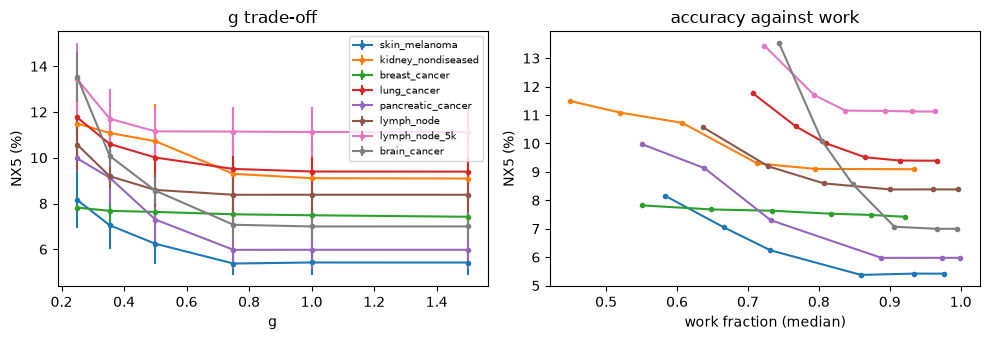

,query,NX5,n_found,share_short10
key,,,,
skin_melanoma,85,0.067659,249,0.043011
kidney_nondiseased,41,0.082742,44,0.153846
breast_cancer,166,0.064685,484,0.034314
lung_cancer,20,0.098197,642,0.023529
pancreatic_cancer,105,0.087408,161,0.056769
lymph_node,21,0.096871,628,0.011494
lymph_node_5k,272,0.124512,3506,0.001292
brain_cancer,515,0.110211,985,0.005650


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for k in data.indexed_keys():
    t = nx[nx.key == k].sort_values("g")
    axs[0].errorbar(t.g, 100 * t.NX5, yerr=100 * t.NX5_sd, marker="o", ms=3, label=k)
    axs[1].plot(t.work_frac, 100 * t.NX5, marker="o", ms=3)
axs[0].set(xlabel="g", ylabel="NX5 (%)", title="g trade-off")
axs[1].set(xlabel="work fraction (median)", ylabel="NX5 (%)", title="accuracy against work")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
pd.DataFrame(typ).set_index("key")[["query", "NX5", "n_found", "share_short10"]]

In [6]:
rio.write_manifest(TOPIC, "R2_whole_tile.ipynb", inputs=["results/_cache (R0_index_cache)"])

wrote results/whole_tile/manifest.json: 51 files; peak memory 0.18 GB


{'topic': 'whole_tile',
 'notebook': 'R2_whole_tile.ipynb',
 'date': '2026-11-05 09:40',
 'tag': 'method-v2',
 'describe': 'method-v3-dirty',
 'commit': 'b35f7d4',
 'inputs': ['results/_cache (R0_index_cache)'],
 'peak_rss_gb': 0.18,
 'notes': '',
 'files': {'band/brain_cancer.npz': {'description': 'brain_cancer: the typical query (seed 0, g = 0.25): d_B to every index tile, rows returned',
   'rows': None,
   'bytes': 37271},
  'band/breast_cancer.npz': {'description': 'breast_cancer: the typical query (seed 0, g = 0.25): d_B to every index tile, rows returned',
   'rows': None,
   'bytes': 9945},
  'band/kidney_nondiseased.npz': {'description': 'kidney_nondiseased: the typical query (seed 0, g = 0.25): d_B to every index tile, rows returned',
   'rows': None,
   'bytes': 5063},
  'band/lung_cancer.npz': {'description': 'lung_cancer: the typical query (seed 0, g = 0.25): d_B to every index tile, rows returned',
   'rows': None,
   'bytes': 9210},
  'band/lymph_node.npz': {'description